*Mathematical Foundations of Robotics · Chapter 4 — Inverse Kinematics*

# 4.1 Solvability: Existence, Multiplicity and the Manipulator Subspace

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/04-inverse-kinematics/4.1-solvability.ipynb)

Forward kinematics always has exactly one answer; **inverse kinematics** may have none, one, several, or
infinitely many. A controller that is asked to place a tool at a given pose must therefore answer three questions
in order: *does a solution exist?*, *how many are there?* and only then *how do I compute them?* This notebook
settles the first two. It defines the reachable and dexterous workspaces, proves the annulus theorem for the
two-link arm, explains why solutions come in pairs, introduces the manipulator subspace of arms with fewer than six
joints, separates redundancy from dexterity, and measures the workspace of a real UR5e in the MuJoCo simulator.

| | |
|:--|:--|
| **Primary reading** | Craig, *Introduction to Robotics: Mechanics and Control*, 3rd ed., §4.1–4.3 |
| **Parallel reading** | Lynch & Park, *Modern Robotics*, §2.5 (task space and workspace) and §6.1 · Siciliano et al., *Robotics: Modelling, Planning and Control*, Ch. 2 (workspace, kinematic redundancy, inverse kinematics) · Spong, Hutchinson & Vidyasagar, *Robot Modeling and Control*, 2nd ed., the inverse-kinematics chapter · Corke, *Robotics, Vision and Control*, Ch. 7 |
| **Lectures** | [Prof. G. C. Nandi, Lecture 3 — Simple concepts of forward and inverse kinematics](https://www.youtube.com/watch?v=2ww-3c08BIs) · [Modern Robotics 2.5 Task space and workspace](https://www.youtube.com/watch?v=hTuW51CpUg4) · [Modern Robotics Ch. 6 Inverse kinematics of open chains](https://www.youtube.com/watch?v=nin2TbMuhR0) |
| **Prerequisites** | Chapter 2 (homogeneous transforms) and Chapter 3 (D-H parameters and forward kinematics) |
| **Study time** | about 2½ hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. state the inverse kinematics problem and explain why it is harder than forward kinematics (twelve numbers, six independent equations, all transcendental);
2. define the **reachable** and **dexterous** workspaces, and derive them for the planar two-link and three-link arms;
3. explain geometrically why solutions occur in pairs ("elbow up" and "elbow down"), and state how many solutions typical arms have;
4. define the **manipulator subspace** of an arm with $n<6$ joints, test whether a goal frame lies in it, and project a goal that does not;
5. distinguish **redundancy** (more joints than the task needs) from **dexterity** (freedom to orient the tool), and describe self-motion;
6. choose among several solutions using joint limits and proximity to the present configuration;
7. measure the reachable workspace and a dexterity map of a real UR5e with MuJoCo.

## Contents

1. [The inverse kinematics problem](#1.-The-inverse-kinematics-problem)
2. [Existence of solutions: the workspace](#2.-Existence-of-solutions:-the-workspace)
3. [Multiple solutions](#3.-Multiple-solutions)
4. [The manipulator subspace when n < 6](#4.-The-manipulator-subspace-when-n-%3C-6)
5. [Redundancy and dexterity](#5.-Redundancy-and-dexterity)
6. [A real robot: the workspace of the UR5e](#6.-A-real-robot:-the-workspace-of-the-UR5e)
7. [Choosing one solution](#7.-Choosing-one-solution)
8. [Worked examples](#8.-Worked-examples)
9. [Summary, common mistakes and exercises](#9.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import mujoco_utils as mju, robots, ik
from rgkit.kinematics import planar_fk
from rgkit.plotting import ACCENT
import mujoco
from matplotlib.patches import Circle, Wedge

def draw_arm(ax, L, q, color="#1f4e79", lw=5, alpha=1.0, ls="-", label=None, base=(0.0, 0.0), zorder=3):
    """Draw a planar nR arm (links as thick lines, joints as dots, tool tip in orange)."""
    pts = planar_fk(L, q) + np.asarray(base)
    ax.plot(pts[:, 0], pts[:, 1], ls, color=color, lw=lw, alpha=alpha, solid_capstyle="round", label=label, zorder=zorder)
    ax.plot(pts[:-1, 0], pts[:-1, 1], "o", color="k", ms=6, alpha=alpha, zorder=zorder + 1)
    ax.plot(*pts[-1], "o", color=ACCENT, ms=7, alpha=alpha, zorder=zorder + 2)

## 1. The inverse kinematics problem

Chapter 3 built the **forward kinematics** of a serial arm: a function $F$ that turns the vector of joint
variables $\boldsymbol\theta=(\theta_1,\dots,\theta_n)$ into the pose of the tool,

$$
{}^{0}_{N}T = F(\boldsymbol\theta) = {}^{0}_{1}T(\theta_1)\,{}^{1}_{2}T(\theta_2)\cdots{}^{N-1}_{N}T(\theta_n)\,.
$$

This is a product of matrices and always returns one answer. Practical tasks are posed the other way round:
*the gripper must be **here**, pointing **this** way; which joint values put it there?* That is the
**inverse kinematics** (IK) problem: given a desired pose ${}^{0}_{N}T_{\text{goal}}$, find all $\boldsymbol\theta$ with
$F(\boldsymbol\theta)={}^{0}_{N}T_{\text{goal}}$.

**Counting equations.** A pose is a $4\times4$ matrix, but its last row is constant, leaving twelve numbers: three
for the position and nine for the rotation matrix. The nine rotation entries are not independent — they obey
the six orthonormality conditions $R^{\mathsf T}R=I$ — so a pose carries only $3+3=6$ independent numbers. Equating them
to the forward-kinematic expressions gives **six independent equations in six unknowns** for a six-joint arm.
The equations are:

* **nonlinear and transcendental** — the unknowns occur inside sines and cosines, multiplied together — so no matrix inversion solves them;
* possibly **without a solution** (the goal is out of reach or needs an orientation the arm cannot produce);
* possibly **with several solutions** (one tool pose reached with the elbow up or down) or infinitely many (redundant arms, singular configurations).

Craig organises the study of IK around three questions, and this chapter follows them:

| Question | Where answered |
|:--|:--|
| Does a solution **exist**? | this notebook (workspace, subspace) |
| How **many** solutions are there? | this notebook (multiplicity) |
| How do we **compute** them? | closed form: 4.2 *(planned)*, 4.3 *(planned)*, 4.4 *(planned)*; iteratively: 4.5 *(planned)*, 4.6 *(planned)* |

**A picture of the problem.** The forward map of the planar two-link arm sends the *joint space* — here the square
$-\pi<\theta_1,\theta_2\le\pi$, which is really a torus because angles wrap — to the *task space*, the plane of tip
positions. The figure draws both. Lines of constant $\theta_1$ (coloured) and of constant $\theta_2$ (grey) in the
left panel become the circles and curves of the right panel. The map is not one-to-one: it **folds** the joint
space along the lines $\theta_2=0$ and $\theta_2=\pm\pi$ (dashed), which land on the two boundary circles of the
reachable region. A point strictly inside is covered twice — once by each half of the fold — which is exactly the
statement that the arm has two solutions there.

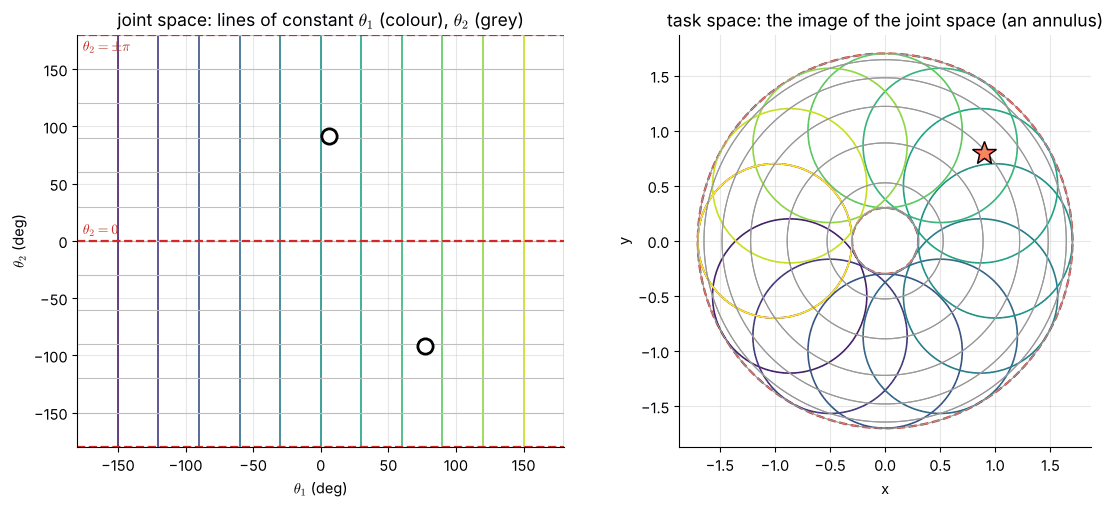

two joint-space points (circles) are mapped to the one task-space point (star):
   q = [ 6.11 91.64] deg  ->  tip [0.9 0.8]
   q = [ 77.16 -91.64] deg  ->  tip [0.9 0.8]


In [2]:
L1, L2 = 1.0, 0.7
target = np.array([0.9, 0.8])
sols = ik.ik_2r(*target, L1, L2)                    # the two solutions found in notebook 4.2

fig, (axj, axt) = plt.subplots(1, 2, figsize=(11.5, 5.2))
th1 = np.linspace(-np.pi, np.pi, 400)
cmap = plt.cm.viridis
for t1 in np.linspace(-np.pi, np.pi, 13):
    th2 = np.linspace(-np.pi, np.pi, 400)
    axj.plot(np.full_like(th2, np.degrees(t1)), np.degrees(th2), color=cmap((t1 + np.pi) / (2 * np.pi)), lw=1.2)
    tip = np.array([L1 * np.cos(t1) + L2 * np.cos(t1 + th2), L1 * np.sin(t1) + L2 * np.sin(t1 + th2)])
    axt.plot(*tip, color=cmap((t1 + np.pi) / (2 * np.pi)), lw=1.2)
for t2 in np.linspace(-np.pi, np.pi, 13):
    tip = np.array([L1 * np.cos(th1) + L2 * np.cos(th1 + t2), L1 * np.sin(th1) + L2 * np.sin(th1 + t2)])
    axt.plot(*tip, color="0.6", lw=0.8)
    axj.plot(np.degrees(th1), np.full_like(th1, np.degrees(t2)), color="0.75", lw=0.8)
for t2, lab in [(0.0, r"$\theta_2=0$"), (np.pi, r"$\theta_2=\pm\pi$"), (-np.pi, None)]:
    axj.axhline(np.degrees(t2), color="#d62728", ls="--", lw=1.6)
    if lab: axj.text(-176, np.degrees(t2) + (6 if t2 == 0 else -14), lab, color="#d62728", fontsize=10)
for r, lab in [(L1 + L2, "outer boundary"), (abs(L1 - L2), "inner boundary")]:
    axt.add_patch(Circle((0, 0), r, fill=False, ec="#d62728", ls="--", lw=1.6))
for q in sols:
    axj.plot(*np.degrees(q), "o", mfc="white", mec="k", mew=2, ms=11, zorder=5)
axt.plot(*target, "*", color=ACCENT, ms=18, zorder=6, mec="k")
axj.set(xlabel=r"$\theta_1$ (deg)", ylabel=r"$\theta_2$ (deg)", title="joint space: lines of constant $\\theta_1$ (colour), $\\theta_2$ (grey)", xlim=(-180, 180), ylim=(-180, 180))
axt.set(xlabel="x", ylabel="y", title="task space: the image of the joint space (an annulus)", aspect="equal")
fig.tight_layout(); plt.show()
print("two joint-space points (circles) are mapped to the one task-space point (star):")
for q in sols:
    print("   q =", np.degrees(q).round(2), "deg  ->  tip", ik.fk_2r(q, L1, L2).round(6))

## 2. Existence of solutions: the workspace

A solution can exist only if the goal lies inside the arm's **workspace**. Craig distinguishes two sets
(Craig §4.2):

* the **reachable workspace** is the set of positions the tool origin can reach with *at least one* orientation;
* the **dexterous workspace** is the set of positions it can reach with *every* orientation.

The dexterous workspace is contained in the reachable one and is frequently small or empty. Both depend on the
tool frame that is chosen: moving the tool frame along the last link changes the sets.

> **Theorem 4.1 (workspace of the planar 2R arm).** The tip of a two-link arm with link lengths $L_1,L_2$ can
> reach a point $\mathbf p$ if and only if
> $$|L_1-L_2|\ \le\ \lVert\mathbf p\rVert\ \le\ L_1+L_2 .$$
> The reachable workspace is therefore an **annulus** of outer radius $L_1+L_2$ and inner radius $|L_1-L_2|$.

*Proof.* The base $O$, the elbow $E$ and the tip $P$ form a triangle (possibly degenerate) with sides
$|OE|=L_1$, $|EP|=L_2$ and $|OP|=r=\lVert\mathbf p\rVert$. The triangle inequality gives
$|L_1-L_2|\le r\le L_1+L_2$, so the condition is necessary. Conversely, if the condition holds, the circle of radius
$L_1$ about $O$ and the circle of radius $L_2$ about $P$ intersect (two circles whose centres are $r$ apart
intersect exactly when $|L_1-L_2|\le r\le L_1+L_2$), and every intersection point is a valid elbow position.
When $r$ equals either bound the circles are tangent and there is one elbow (a *stretched* or *folded* arm);
otherwise there are two intersection points, mirror images in the line $OP$. $\blacksquare$

The same argument shows that the two-link arm has **no dexterous workspace** unless $L_1=L_2$: at an interior
point the elbow has only two positions, so the orientation $\phi=\theta_1+\theta_2$ of the last link takes only two
values. If $L_1=L_2$ the inner radius is zero, and at the origin the arm folds back on itself with $\theta_1$
arbitrary, so every orientation is available there — but only there.

**Three links add one orientation.** For the planar 3R arm with link lengths $L_1,L_2,L_3$ the tool pose is
$(x,y,\phi)$ with $\phi=\theta_1+\theta_2+\theta_3$. Fix the tool orientation $\phi$. The *wrist point*
$\mathbf w=\mathbf p-L_3(\cos\phi,\sin\phi)$ must lie in the 2R annulus $A=\{|L_1-L_2|\le\lVert\mathbf w\rVert\le L_1+L_2\}$.
As $\phi$ varies, $\mathbf w$ runs over the circle of radius $L_3$ about $\mathbf p$, whose points lie at distances from the origin
between $\bigl|\lVert\mathbf p\rVert-L_3\bigr|$ and $\lVert\mathbf p\rVert+L_3$. Hence, writing $r=\lVert\mathbf p\rVert$:

$$
\text{reachable:}\quad \max\bigl(0,\ |L_1-L_2|-L_3\bigr)\le r\le L_1+L_2+L_3,
$$

$$
\text{dexterous:}\quad r+L_3\le L_1+L_2\quad\text{and}\quad\bigl|\,r-L_3\bigr|\ge|L_1-L_2| .
$$

(The first condition says that the wrist circle does not stick out of the outer boundary; the second that it
does not enter the hole.) The next cell tests these formulae by brute force: for every point of a grid it
asks the closed-form solver of Chapter 4.2 whether a solution exists for each of 360 tool orientations.

In [3]:
L = (1.0, 0.8, 0.5)                                    # link lengths of a planar 3R arm
phis = np.linspace(-np.pi, np.pi, 360, endpoint=False)

def reachable_phi_fraction(p):
    """Fraction of 360 tool orientations for which the 3R arm has an IK solution at position p."""
    return np.mean([len(ik.ik_3r_planar(p[0], p[1], f, *L)) > 0 for f in phis])

def theory_reachable(r):   return max(0.0, abs(L[0] - L[1]) - L[2]) - 1e-12 <= r <= sum(L) + 1e-12
def theory_dexterous(r):   return (r + L[2] <= L[0] + L[1] + 1e-12) and (abs(r - L[2]) >= abs(L[0] - L[1]) - 1e-12)

radii = np.linspace(0, 2.5, 251)
frac = np.array([reachable_phi_fraction((r, 0.0)) for r in radii])
brute_reach, brute_dex = frac > 0, frac >= 1.0
print("reachable-workspace formula agrees with brute force at all", len(radii), "radii:",
      all(brute_reach[i] == theory_reachable(r) for i, r in enumerate(radii)))
print("dexterous-workspace formula agrees with brute force:",
      all(brute_dex[i] == theory_dexterous(r) for i, r in enumerate(radii)))
dex_rings = [(radii[i], radii[j]) for i, j in [(0, 0)]]
inside = [r for r, d in zip(radii, brute_dex) if d]
print(f"dexterous radii found: 0 <= r <= {max(r for r in inside if r < 0.5):.2f} and {min(r for r in inside if r > 0.5):.2f} <= r <= {max(inside):.2f}")

reachable-workspace formula agrees with brute force at all 251 radii: True
dexterous-workspace formula agrees with brute force: True
dexterous radii found: 0 <= r <= 0.30 and 0.70 <= r <= 1.30


For $L=(1.0,\,0.8,\,0.5)$ the dexterous workspace consists of a small central disc $r\le0.3$ together with a ring
$0.7\le r\le1.3$; between them (and outside up to $r=2.3$) the arm reaches the point but not with every
orientation. The figure shows the three regions, the orientation fraction on a radial cut, and a
two-dimensional map of the same quantity — the **dexterity index** — computed from the solver.

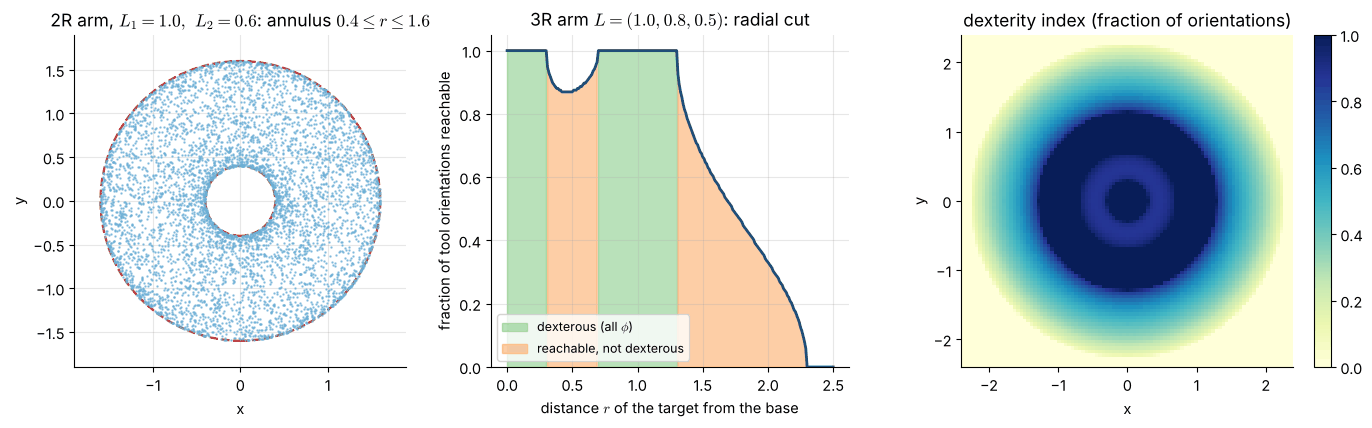

In [4]:
xs = np.linspace(-2.4, 2.4, 97)
Z = np.array([[reachable_phi_fraction((x, y)) for x in xs] for y in xs])

fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
# (a) the 2R annulus, with sampled tip positions
rng = np.random.default_rng(0)
t = rng.uniform(-np.pi, np.pi, (6000, 2))
tips = np.array([ik.fk_2r(q, 1.0, 0.6) for q in t])
axs[0].plot(*tips.T, ".", ms=1.5, color="#6baed6", alpha=0.7)
for r in (1.6, 0.4):
    axs[0].add_patch(Circle((0, 0), r, fill=False, ec="#d62728", ls="--", lw=1.6))
axs[0].set(title=r"2R arm, $L_1=1.0,\ L_2=0.6$: annulus $0.4\leq r\leq1.6$", aspect="equal", xlim=(-1.9, 1.9), ylim=(-1.9, 1.9), xlabel="x", ylabel="y")
# (b) radial cut
axs[1].plot(radii, frac, color="#1f4e79", lw=2)
axs[1].fill_between(radii, 0, frac, where=brute_dex, color="#74c476", alpha=0.5, label="dexterous (all $\\phi$)")
axs[1].fill_between(radii, 0, frac, where=brute_reach & ~brute_dex, color="#fdae6b", alpha=0.6, label="reachable, not dexterous")
axs[1].set(xlabel=r"distance $r$ of the target from the base", ylabel="fraction of tool orientations reachable",
           title=r"3R arm $L=(1.0,0.8,0.5)$: radial cut", ylim=(0, 1.05)); axs[1].legend(loc="lower left", fontsize=9)
# (c) 2D map
im = axs[2].imshow(Z, extent=[xs[0], xs[-1], xs[0], xs[-1]], origin="lower", cmap="YlGnBu", vmin=0, vmax=1)
axs[2].set(title="dexterity index (fraction of orientations)", xlabel="x", ylabel="y")
plt.colorbar(im, ax=axs[2], fraction=0.046); axs[2].grid(False)
fig.tight_layout(); plt.show()

**Joint limits.** Real joints rarely turn through a full revolution. Limits remove part of the workspace — and, as
Section 7 shows, remove individual *solutions* even where the workspace remains. The explorer below samples random
configurations of a planar 3R arm inside user-chosen limits and overlays the unrestricted annuli. Try shrinking
the range of the elbow joint $\theta_2$: the hole in the middle grows and the region of the fully dexterous ring
shrinks, although the outer radius is unchanged as long as the arm can still stretch out.

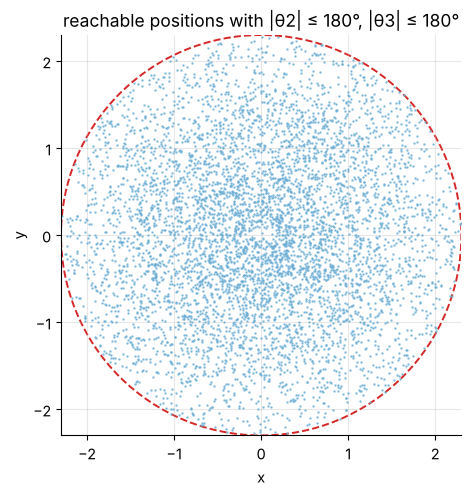

In [5]:
def explore_workspace(L1=1.0, L2=0.8, L3=0.5, theta2_range=180, theta3_range=180):
    rng = np.random.default_rng(1)
    q = np.column_stack([rng.uniform(-np.pi, np.pi, 6000),
                         rng.uniform(-deg(theta2_range), deg(theta2_range), 6000),
                         rng.uniform(-deg(theta3_range), deg(theta3_range), 6000)])
    ang = np.cumsum(q, axis=1)
    tip = np.column_stack([L1 * np.cos(ang[:, 0]) + L2 * np.cos(ang[:, 1]) + L3 * np.cos(ang[:, 2]),
                           L1 * np.sin(ang[:, 0]) + L2 * np.sin(ang[:, 1]) + L3 * np.sin(ang[:, 2])])
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    ax.plot(*tip.T, ".", ms=1.6, color="#6baed6", alpha=0.7)
    R = L1 + L2 + L3
    for r, st in [(R, "--"), (max(0, abs(L1 - L2) - L3), "--")]:
        ax.add_patch(Circle((0, 0), r, fill=False, ec="#d62728", ls=st, lw=1.4))
    ax.set(xlim=(-R, R), ylim=(-R, R), aspect="equal", xlabel="x", ylabel="y",
           title=f"reachable positions with |θ2| ≤ {theta2_range}°, |θ3| ≤ {theta3_range}°")
    plt.show()

interact(explore_workspace,
         L1=widgets.FloatSlider(1.0, min=0.3, max=1.5, step=0.1, description="L1"),
         L2=widgets.FloatSlider(0.8, min=0.3, max=1.5, step=0.1, description="L2"),
         L3=widgets.FloatSlider(0.5, min=0.1, max=1.0, step=0.1, description="L3"),
         theta2_range=widgets.IntSlider(180, min=20, max=180, step=10, description="|θ2| max (°)"),
         theta3_range=widgets.IntSlider(180, min=20, max=180, step=10, description="|θ3| max (°)"));

## 3. Multiple solutions

Inside the workspace a goal is usually reached by **more than one** joint vector. For the two-link arm the reason
is the one found in the proof of Theorem 4.1: the elbow may sit at either intersection of the two circles, which
are mirror images in the line from the base to the tip. Reflecting the elbow in that line flips the sign of
$\theta_2$ and changes $\theta_1$ by twice the angle between link 1 and the line.

We follow the convention of the course notes: for a target in the right half-plane, $\theta_2>0$ (anticlockwise
bend) puts the elbow *below* the base–target line — **elbow down** — and $\theta_2<0$ puts it above — **elbow up**.
Because books differ on these names, always state the sign of $\theta_2$ together with the name.

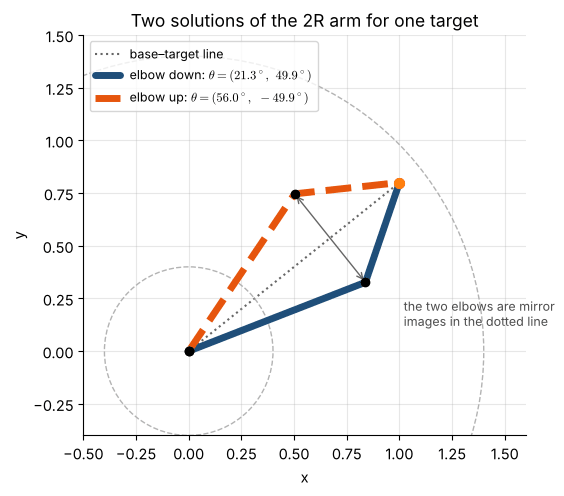

elbow down: theta = [21.29 49.88] deg  -> tip [1.  0.8]
elbow up  : theta = [ 56.03 -49.88] deg  -> tip [1.  0.8]


In [6]:
L1, L2 = 0.9, 0.5
target = np.array([1.0, 0.8])
down, up = ik.ik_2r(*target, L1, L2)                       # rows: theta2 > 0 first, then theta2 < 0

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot([0, target[0]], [0, target[1]], ":", color="0.4", lw=1.5, label="base–target line", zorder=1)
draw_arm(ax, (L1, L2), down, color="#1f4e79", label=rf"elbow down: $\theta=({np.degrees(down[0]):.1f}^\circ,\ {np.degrees(down[1]):.1f}^\circ)$")
draw_arm(ax, (L1, L2), up, color="#e6550d", ls="--", label=rf"elbow up: $\theta=({np.degrees(up[0]):.1f}^\circ,\ {np.degrees(up[1]):.1f}^\circ)$")
ax.add_patch(Circle((0, 0), L1 + L2, fill=False, ec="0.7", ls="--")); ax.add_patch(Circle((0, 0), abs(L1 - L2), fill=False, ec="0.7", ls="--"))
ax.annotate("", xy=planar_fk((L1, L2), down)[1], xytext=planar_fk((L1, L2), up)[1], arrowprops=dict(arrowstyle="<->", color="0.4"))
ax.text(1.02, 0.12, "the two elbows are mirror\nimages in the dotted line", fontsize=9, color="0.3", ha="left")
ax.set(xlim=(-0.5, 1.6), ylim=(-0.4, 1.5), aspect="equal", xlabel="x", ylabel="y", title="Two solutions of the 2R arm for one target")
ax.legend(loc="upper left", fontsize=9); plt.show()
for name, q in (("elbow down", down), ("elbow up", up)):
    print(f"{name:10s}: theta = {np.degrees(q).round(2)} deg  -> tip {ik.fk_2r(q, L1, L2).round(9)}")

The animation moves a target outwards along a ray. Inside the annulus the two postures are mirror images; as the
target approaches the outer boundary they come together, **merge into the single stretched posture** exactly on
the boundary, and vanish when the target leaves the workspace. The same happens at the inner boundary and, more
generally, wherever a "branch" of the solution meets another: *the number of real solutions changes only by
passing through a double root*, which in robotics is a **singular configuration**.

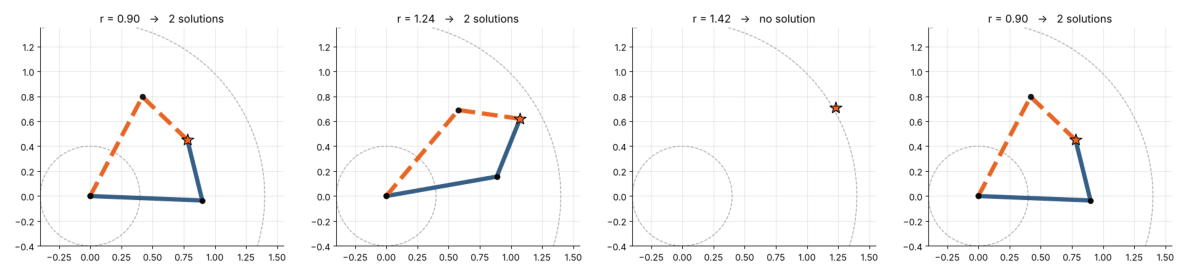

In [7]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ray = np.array([np.cos(deg(30)), np.sin(deg(30))])
radii_path = np.concatenate([np.linspace(0.9, 1.5, 24), np.linspace(1.5, 0.9, 16)])

def update(r):
    ax.cla()
    ax.add_patch(Circle((0, 0), L1 + L2, fill=False, ec="0.65", ls="--")); ax.add_patch(Circle((0, 0), abs(L1 - L2), fill=False, ec="0.65", ls="--"))
    tgt = r * ray
    S = ik.ik_2r(*tgt, L1, L2)
    cols = ["#1f4e79", "#e6550d"]
    for i, q in enumerate(S):
        draw_arm(ax, (L1, L2), q, color=cols[i], ls="-" if i == 0 else "--", alpha=0.9)
    ax.plot(*tgt, "*", color=ACCENT if len(S) else "#d62728", ms=15, mec="k", zorder=8)
    status = {0: "no solution", 1: "1 solution (boundary)", 2: "2 solutions"}[len(S)]
    ax.set(xlim=(-0.4, 1.55), ylim=(-0.4, 1.35), aspect="equal", title=f"r = {r:.2f}   →   {status}")

animate(fig, update, radii_path, interval=110, gif="assets/4.1-two-solutions-merge.gif", n_keyframes=4,
        keyframe_titles=None)

**How many solutions?** Counting depends on the number of joints and on how many link parameters
($a_i$, $\alpha_i$, $d_i$) are non-zero. The table lists the values met in this course; all are *maximum* numbers
over the interior of the workspace.

| Arm (what is specified) | Maximum number of solutions | Where treated |
|:--|:--:|:--|
| planar 2R (position $x,y$) | 2 | 4.2 |
| planar 3R (pose $x,y,\phi$) | 2 | 4.2 |
| articulated 3R (position $x,y,z$) | 4 | 4.3 |
| SCARA RRPR (position and yaw) | 2 | 4.3 |
| 6R with spherical wrist, e.g. PUMA-type | 8 | 4.3 |
| 6R with offset wrist, e.g. Universal Robots | 8 | 4.4 |
| general 6R manipulator | 16 | Craig §4.2; 4.5 (numerical experiment) |

Craig tabulates how the bound for a six-joint revolute arm grows with the number of non-zero link lengths
$a_i$: at most 4 solutions when $a_1=a_3=a_5=0$, at most 8 when $a_3=a_5=0$, and at most 16 once $a_3$ or all link
lengths are non-zero (Craig §4.2). Sixteen is also the largest number a *general* six-joint arm can have; for
such an arm the solutions are roots of a polynomial of degree 16 (Craig §4.5–4.6 sketch this). The more joint
offsets and twists an arm has, the more ways there are to fold it around the same tool pose.

*Infinitely many* solutions arise in two ways: **singularities** (for the 2R arm with $L_1=L_2$ and the target at the
origin the elbow is folded, and $\theta_1$ is arbitrary) and **redundancy** (Section 5).

## 4. The manipulator subspace when $n<6$

An arm with $n$ independent joints can reach only an $n$-dimensional family of tool poses. Craig (§4.3) calls
the set of goal frames that an $n$-joint arm can attain its **manipulator subspace**. A goal outside the
subspace has no exact solution, however far inside the position workspace it lies. Examples:

| Arm | Subspace | Free coordinates |
|:--|:--|:--|
| planar 2R | positions in the plane | $x,y$ |
| planar 3R | goal frames whose $\hat Z$ is parallel to the base $\hat Z$ and whose origin lies in the base plane | $x,y,\phi$ |
| SCARA (RRPR) | $\hat Z$ vertical, any $x,y,z$ | $x,y,z,\phi$ |
| five-joint arm | all positions, but only a two-parameter set of tool-axis directions (no free roll about the tool) | $x,y,z$ and two angles |

For the planar 3R arm the subspace consists of the goal frames

$$
{}^{0}_{3}T_{\text{goal}}=\begin{bmatrix}c_\phi&-s_\phi&0&x\\ s_\phi&c_\phi&0&y\\0&0&1&0\\0&0&0&1\end{bmatrix}.
$$

If a user supplies a goal with a $z$ offset or a tilted tool axis, no joint vector reproduces it. The
usual remedy is to **project** the goal onto the subspace — keep $x$, $y$ and the heading $\phi$ of the
projected $\hat X$ axis — solve for that, and report the residual that was discarded. The function below does this
and is used in Example 4.1.4.

In [8]:
from rgkit.transforms import make_T, rotz, rotx

def project_to_planar_subspace(T):
    """Nearest planar-3R goal (x, y, phi) of a 4x4 goal frame, with the discarded z offset (m) and tilt (rad)."""
    x, y, z = T[:3, 3]
    phi = np.arctan2(T[1, 0], T[0, 0])                 # heading of the tool X axis projected into the plane
    tilt = np.arccos(np.clip(T[2, 2], -1, 1))          # angle between the tool Z axis and the base Z axis
    return (x, y, phi), z, tilt

T_in  = make_T(rotz(deg(40)), [0.8, 0.5, 0.0])                     # lies in the subspace
T_out = make_T(rotz(deg(40)) @ rotx(deg(5)), [0.8, 0.5, 0.04])     # 4 cm above the plane and tilted by 5 degrees
for name, T in (("T_in ", T_in), ("T_out", T_out)):
    (x, y, phi), dz, tilt = project_to_planar_subspace(T)
    print(f"{name}: projected goal (x, y, phi) = ({x:.3f}, {y:.3f}, {np.degrees(phi):.1f} deg);  discarded: z = {dz*1000:.0f} mm, tilt = {np.degrees(tilt):.1f} deg")

T_in : projected goal (x, y, phi) = (0.800, 0.500, 40.0 deg);  discarded: z = 0 mm, tilt = 0.0 deg
T_out: projected goal (x, y, phi) = (0.800, 0.500, 40.0 deg);  discarded: z = 40 mm, tilt = 5.0 deg


## 5. Redundancy and dexterity

Two words are easily confused.

* **Redundancy** is a property of the arm *relative to a task*. An arm is **kinematically redundant** for a task
  that needs $m$ coordinates if it has $n>m$ joints. A planar 3R arm that only has to place its tip at a point
  ($m=2$) is redundant; a seven-joint arm such as the Franka Emika Panda is redundant for any six-dimensional pose task.
  A redundant arm has **infinitely many** solutions, which form a continuous family called *self-motion*: the joints
  move while the tool stands still. The extra freedom can be spent on avoiding obstacles or joint limits
  (Chapter 4.6 and Chapter 5).
* **Dexterity** is the freedom to *orient* the tool at a given point — measured by the dexterous workspace above,
  or by how well-conditioned the Jacobian is (Chapter 5). A redundant arm is usually more dexterous, but the two
  concepts are different: the 3R arm of Section 2 is *not* redundant for a pose task ($m=3$, $n=3$) yet is
  dexterous in a ring around the base.

The figure shows the self-motion of the 3R arm holding its tip at a fixed point $\mathbf p$. Any tool orientation
$\phi$ for which the wrist point lies in the annulus of the first two links gives a solution; sweeping $\phi$ traces a
curve of joint vectors. Left: several postures with the same tip position. Right: the three joint angles along
the self-motion curves of the two branches.

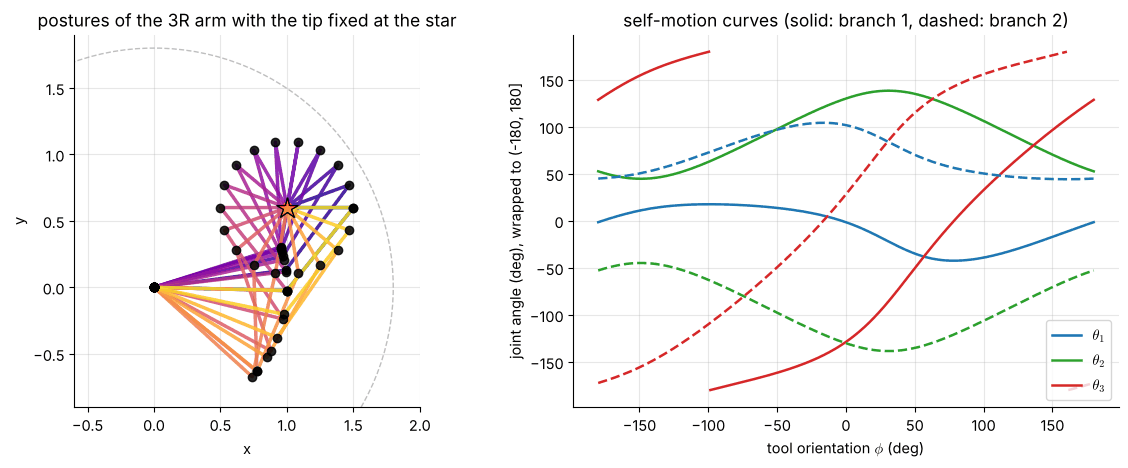

tip fixed at [1.  0.6] (r = 1.166 < 1.3, inside the dexterous ring): every tool orientation has a solution; feasible phi samples per branch: 721 and 721 of 721


In [9]:
L = (1.0, 0.8, 0.5)
p = np.array([1.0, 0.6])
phis = np.linspace(-np.pi, np.pi, 721)
branch = {0: [], 1: []}
for f in phis:
    S = ik.ik_3r_planar(*p, f, *L)
    for i, s in enumerate(S):
        branch[i].append((f, *s))
branch = {k: np.array(v) for k, v in branch.items()}

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.8))
cmap = plt.cm.plasma
samp = branch[0][::40]
for k, row in enumerate(samp):
    draw_arm(a, L, row[1:], color=cmap(k / len(samp)), lw=2.5, alpha=0.85)
a.plot(*p, "*", color=ACCENT, ms=16, mec="k", zorder=9)
a.add_patch(Circle((0, 0), L[0] + L[1], fill=False, ec="0.75", ls="--"))
a.set(aspect="equal", xlim=(-0.6, 2.0), ylim=(-0.9, 1.9), xlabel="x", ylabel="y", title="postures of the 3R arm with the tip fixed at the star")
for i, ls in ((0, "-"), (1, "--")):
    d = branch[i]
    for j, (c, nm) in enumerate(zip(("#1f77b4", "#2ca02c", "#d62728"), (r"$\theta_1$", r"$\theta_2$", r"$\theta_3$"))):
        ang = np.degrees(d[:, j + 1]).copy()
        ang[np.r_[False, np.abs(np.diff(ang)) > 180]] = np.nan          # do not join the curve across the +-180 deg wrap
        b.plot(np.degrees(d[:, 0]), ang, ls, color=c, lw=1.8, label=nm if i == 0 else None)
b.set(xlabel=r"tool orientation $\phi$ (deg)", ylabel="joint angle (deg), wrapped to (-180, 180]", title="self-motion curves (solid: branch 1, dashed: branch 2)")
b.legend(); fig.tight_layout(); plt.show()
print(f"tip fixed at {p} (r = {np.hypot(*p):.3f} < 1.3, inside the dexterous ring): every tool orientation has a solution;",
      "feasible phi samples per branch:", len(branch[0]), "and", len(branch[1]), "of", len(phis))

## 6. A real robot: the workspace of the UR5e

We now measure the workspace of the **Universal Robots UR5e**, taking the model from
[MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie) (downloaded on first use). Sampling
random joint vectors and reading the tool position from the simulator is a Monte-Carlo estimate of the reachable
workspace. Because joint 1 can turn through a full revolution, the workspace is a body of revolution about the
vertical axis, so the plot uses cylindrical coordinates $(\rho,z)$ with $\rho=\sqrt{x^2+y^2}$; the cloud is its
meridian section. The nominal reach quoted by the manufacturer is $850$ mm.

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)
stretched arm: wrist point 0.823 m from the shoulder, flange site 0.829 m (manufacturer's nominal reach: 0.850 m)
largest sampled distance of the flange site from the shoulder: 1.098 m  <=  wrist reach + 0.1 m = 0.923 m: False
tool heights sampled: -0.78 .. 1.11 m;   horizontal distances: 0.03 .. 0.96 m


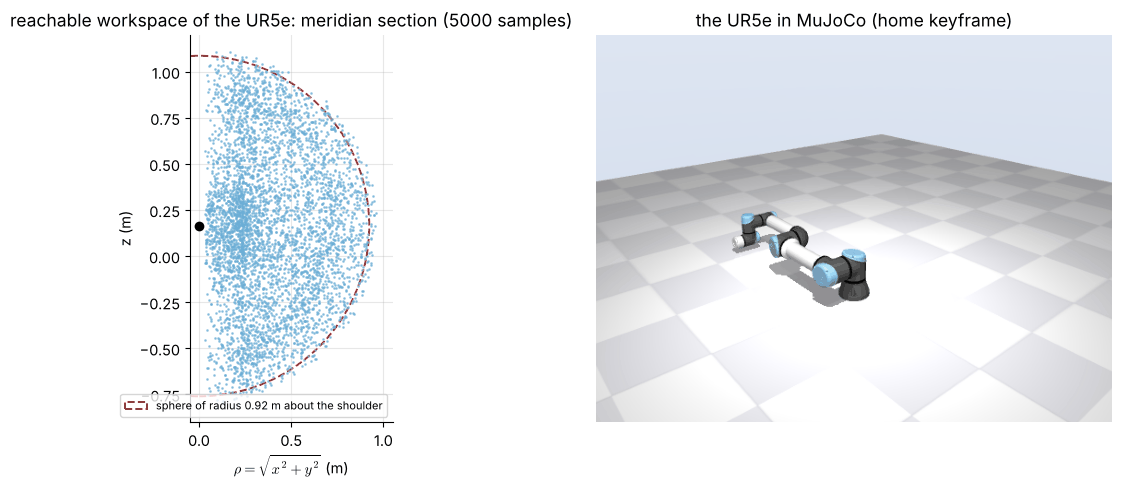

In [10]:
model, data = robots.load_robot("ur5e")
print(robots.describe("ur5e"))
arm = ik.MujocoArm(model, data, "attachment_site")
rng = np.random.default_rng(3)
lo = np.maximum(model.jnt_range[:, 0], -np.pi); hi = np.minimum(model.jnt_range[:, 1], np.pi)
Q = rng.uniform(lo, hi, (5000, 6))
tips = np.array([arm.fk(q)[:3, 3] for q in Q])
mujoco.mj_resetData(model, data); mujoco.mj_forward(model, data)               # all joints at zero: the arm is stretched out
shoulder = data.xanchor[1].copy()                                              # joint 2 (shoulder lift): 0.163 m above the base
wrist_pt = data.xanchor[5].copy()                                              # intersection of wrist axes 5 and 6
reach_wrist = np.linalg.norm(wrist_pt - shoulder)
bound = reach_wrist + 0.1                                                      # the flange site is 0.1 m beyond the wrist point
rho, z = np.hypot(tips[:, 0], tips[:, 1]), tips[:, 2]
dist = np.linalg.norm(tips - shoulder, axis=1)
print(f"stretched arm: wrist point {reach_wrist:.3f} m from the shoulder, flange site {np.linalg.norm(arm.fk(np.zeros(6))[:3, 3] - shoulder):.3f} m (manufacturer's nominal reach: 0.850 m)")
print(f"largest sampled distance of the flange site from the shoulder: {dist.max():.3f} m  <=  wrist reach + 0.1 m = {bound:.3f} m: {dist.max() <= bound + 1e-9}")
print(f"tool heights sampled: {z.min():.2f} .. {z.max():.2f} m;   horizontal distances: {rho.min():.2f} .. {rho.max():.2f} m")

fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw=dict(width_ratios=[1, 1.1]))
a.plot(rho, z, ".", ms=2, color="#6baed6", alpha=0.6)
a.add_patch(Circle((0, shoulder[2]), bound, fill=False, ec="#d62728", ls="--", lw=1.4, label=f"sphere of radius {bound:.2f} m about the shoulder"))
a.plot(0, shoulder[2], "ko"); a.set(aspect="equal", xlabel=r"$\rho=\sqrt{x^2+y^2}$ (m)", ylabel="z (m)", xlim=(-0.05, 1.05), ylim=(-0.9, 1.2),
                              title="reachable workspace of the UR5e: meridian section (5000 samples)")
a.legend(loc="lower right", fontsize=8)
view = dict(azimuth=140, elevation=-22, distance=2.2, lookat=(0, 0, 0.35))
b.imshow(mju.render(model, data, camera=view, width=560, height=420)); b.axis("off"); b.set_title("the UR5e in MuJoCo (home keyframe)")
fig.tight_layout(); plt.show()

The cloud has the shape one expects of an arm with two long links and a compact wrist: its outer envelope is the
sphere about the shoulder whose radius is the stretched reach of the *wrist point* (the intersection of wrist axes 5 and 6,
$0.83$ m from the shoulder) plus the $0.1$ m of flange offset, which the wrist can point radially outwards. The
manufacturer's nominal reach of $0.85$ m refers to the stretched arm. The tool can go below the base plane (down to
about $z=-0.7$ m), and — unlike the 2R annulus — it can reach points close to the base axis, because the
$0.134$ m lateral offset acts on the *wrist point*, not on the tool.

**Dexterity map.** Reaching a point is only half the story; the tool must usually arrive with a prescribed
orientation. We estimate the dexterity index of the UR5e at points of the meridian plane: for each point we draw 100
random tool orientations (uniform on $SO(3)$) and count how many have **at least one** inverse-kinematics solution,
using the closed-form solver developed in Notebook 4.4. (All six joints of the real UR5e turn through
$\pm360^\circ$, so every solution modulo $2\pi$ is admissible.) The result is the fraction of orientations that
the arm can realise at that point.

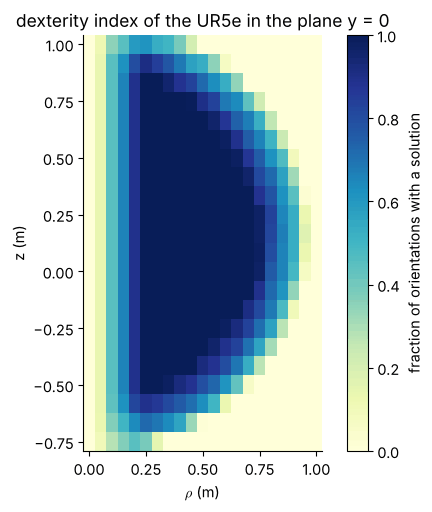

cells with index 1.0 (all 100 sampled orientations solvable): 125 of 462
  they span rho = 0.25 .. 0.70 m and z = -0.50 .. 0.83 m
index at rho = 0.05 m (near the base axis): mean 0.14;   at rho = 0.95 m (outer rim): mean 0.02


In [11]:
from scipy.spatial.transform import Rotation
UR5E = ik.URGeometry(d1=0.163, a2=0.425, a3=0.392, d4=0.134, d5=0.1, d6=0.1)       # measured from the MuJoCo model in notebook 4.4
rots = Rotation.random(100, random_state=5).as_matrix()
rr = np.linspace(0.0, 1.0, 21); zz = np.linspace(-0.75, 1.0, 22)
D = np.zeros((len(zz), len(rr)))
for i, zi in enumerate(zz):
    for j, rj in enumerate(rr):
        n = 0
        for R in rots:
            T = np.eye(4); T[:3, :3] = R; T[:3, 3] = [rj, 0.0, zi]
            n += len(ik.ik_ur(T, UR5E)) > 0
        D[i, j] = n / len(rots)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(D, origin="lower", extent=[rr[0] - 0.025, rr[-1] + 0.025, zz[0] - 0.04, zz[-1] + 0.04], cmap="YlGnBu", vmin=0, vmax=1, aspect="equal")
plt.colorbar(im, ax=ax, fraction=0.046, label="fraction of orientations with a solution")
ax.set(xlabel=r"$\rho$ (m)", ylabel="z (m)", title="dexterity index of the UR5e in the plane y = 0"); ax.grid(False)
plt.show()
full = D >= 1.0
ii, jj = np.nonzero(full)
print(f"cells with index 1.0 (all 100 sampled orientations solvable): {full.sum()} of {D.size}")
print(f"  they span rho = {rr[jj].min():.2f} .. {rr[jj].max():.2f} m and z = {zz[ii].min():.2f} .. {zz[ii].max():.2f} m")
print(f"index at rho = 0.05 m (near the base axis): mean {D[:, 1].mean():.2f};   at rho = 0.95 m (outer rim): mean {D[:, -2].mean():.2f}")

Unlike the planar arms of Section 2, the six-joint UR5e has a **large dexterous workspace**: a thick shell of
points (index $1.0$ in the map) at which *every* sampled orientation can be realised. The index falls off towards
the outer envelope, where the arm is nearly stretched out and only orientations compatible with that posture
remain, and towards the base axis: the wrist point cannot enter the cylinder of radius $0.134$ m
about the axis (the lateral offset $d_4$), so only orientations that push the wrist point outwards are possible there.
As a spot check we take a goal pose, solve it, and hand every solution to MuJoCo: each must reproduce the same
flange pose. (The derivation behind the solver is the subject of Notebook 4.4.)

In [12]:
mujoco.mj_forward(model, data)
Rb, pb = data.body("base").xmat.reshape(3, 3).copy(), data.body("base").xpos.copy()        # UR "base_link" frame {0}
T_wb = make_T(Rb, pb); Rpi = make_T(rotz(np.pi))                                           # world<-base ; site = flange rotated by pi about z6

T_goal = make_T(Rotation.random(random_state=11).as_matrix(), [0.35, 0.10, 0.30])          # a pose in {0}
S = ik.ik_ur(T_goal, UR5E)
print("number of inverse-kinematics solutions found:", len(S))
errs = [np.abs(arm.fk(q) - T_wb @ T_goal @ Rpi).max() for q in S]
print("max |MuJoCo site pose - goal| over the solutions:", f"{max(errs):.1e}")

number of inverse-kinematics solutions found: 8
max |MuJoCo site pose - goal| over the solutions: 8.9e-16


## 7. Choosing one solution

A controller must return a *single* joint vector. Craig (§4.2) lists the usual rules, and a closed-form solver is
valuable precisely because it supplies **all** candidates to choose from:

1. **Discard** solutions that violate joint limits (taking account of the $2\pi$ periodicity: an angle of
   $-200^\circ$ may be realised as $+160^\circ$ if the joint range allows it).
2. **Prefer the solution nearest the present configuration**, with larger weights on the large, slow proximal joints
   than on the light wrist joints, so that the motion is short and quick.
3. **Avoid** solutions that make the arm collide with the workspace or itself (needs a geometric model).
4. When following a path, **keep to one branch** so that the joints move continuously (Notebook 4.2).

The helper functions `ik.within_limits` and `ik.nearest_solution` implement rules 1–2. In the example the two
solutions of Section 3 are filtered by a limit $0^\circ\le\theta_2\le140^\circ$ and then ranked by distance from the current posture.

In [13]:
sol = ik.ik_2r(1.0, 0.8, 0.9, 0.5)                      # [[21.29, 49.88], [56.03, -49.88]] deg  (Section 3)
q_now = deg(np.array([40.0, -20.0]))
lower, upper = deg(np.array([-90.0, 0.0])), deg(np.array([180.0, 140.0]))
ok = ik.within_limits(sol, lower, upper)
i_all, q_all = ik.nearest_solution(sol, q_now)
i_ok, q_ok = ik.nearest_solution(sol[ok], q_now)
print("solutions (deg):\n", np.degrees(sol).round(2))
print("within limits:", ok)
print("nearest to the present configuration (no limits):", np.degrees(q_all).round(2), "deg")
print("nearest after discarding limit violations      :", np.degrees(q_ok).round(2), "deg")

solutions (deg):
 [[ 21.29  49.88]
 [ 56.03 -49.88]]
within limits: [ True False]
nearest to the present configuration (no limits): [ 56.03 -49.88] deg
nearest after discarding limit violations      : [21.29 49.88] deg


## 8. Worked examples

**Example 4.1.1 — workspace and number of solutions of a 2R arm.** A two-link arm has $L_1=0.9$ m and
$L_2=0.5$ m. How many solutions has each of the targets $A=(1.0,\ 0.8)$, $B=(0.3,\ 0.2)$ and $C=(1.4,\ 0)$?

*Solution.* By Theorem 4.1 the reachable annulus is $0.4\le r\le1.4$. Target $A$ has $r=\sqrt{1.64}=1.281$, which lies
strictly inside: **two** solutions. Target $B$ has $r=0.361<0.4$: it lies in the hole, **no** solution. Target $C$
has $r=1.4=L_1+L_2$: on the outer boundary, **one** solution (the stretched arm, $\boldsymbol\theta=(0,0)$).

**Example 4.1.2 — both solutions for target $A$.** Give them and verify by forward kinematics.

*Solution.* Section 3 obtains $\theta_2=\pm49.88^\circ$ and the matching $\theta_1=21.29^\circ$ (for $\theta_2>0$, elbow down) and
$56.03^\circ$ (for $\theta_2<0$, elbow up). Substituting into $x=L_1c_1+L_2c_{12}$ and $y=L_1s_1+L_2s_{12}$ returns $(1.0,\ 0.8)$ in both cases.
(The derivation of these numbers is the subject of Notebook 4.2.)

**Example 4.1.3 — the dexterous workspace of a 3R arm.** For $L=(1.0,\ 0.8,\ 0.5)$ find the dexterous workspace, and the
range of tool orientations that are *not* available at $\mathbf p=(0.5,\ 0)$.

*Solution.* With $|L_1-L_2|=0.2$ and $L_3=0.5$ the conditions of Section 2 read $r\le1.8-0.5=1.3$ and $|r-0.5|\ge0.2$,
i.e. $r\le0.3$ or $0.7\le r\le1.3$: a disc and a ring. The point $r=0.5$ lies in the gap. There the wrist point
$\mathbf w=\mathbf p-0.5(\cos\phi,\sin\phi)$ has $\lVert\mathbf w\rVert^2=0.5-0.5\cos\phi$, which must be at least $0.2^2=0.04$, i.e. $\cos\phi\le0.92$,
or $|\phi|\ge23.07^\circ$. The tool cannot point within $\pm23.07^\circ$ of the $+x$ direction, so
$1-2\cdot23.07/360=87.2\%$ of all orientations are available.

**Example 4.1.4 — is the goal in the subspace?** A planar 3R arm is given the goal frame
$T=\mathrm{Trans}(0.8,\,0.5,\,0.04)\,R_Z(40^\circ)R_X(5^\circ)$. Can it be attained?

*Solution.* The goal has $z=0.04$ m and its $\hat Z$ axis is tilted by $5^\circ$ from the base $\hat Z$, so it is **not** in the
subspace $\{z=0,\ \hat Z\parallel\hat Z_0\}$ and no exact solution exists. Projection gives
$(x,y,\phi)=(0.8,\ 0.5,\ 40^\circ)$ with residuals $40$ mm and $5^\circ$; the arm can attain the projected goal.

**Example 4.1.5 — joint limits remove a solution.** Target $A$ of Example 4.1.1 is to be reached with $0^\circ\le\theta_2\le140^\circ$.
Which solution survives, and which would be chosen from the present posture $\boldsymbol\theta=(40^\circ,\,-20^\circ)$ without limits?

*Solution.* The elbow-up solution has $\theta_2=-49.88^\circ$, outside the limit; only the elbow-down solution
$(21.29^\circ,\ 49.88^\circ)$ survives. Without limits the distances to $\boldsymbol\theta_{\rm now}=(40^\circ,-20^\circ)$ are $\sqrt{18.71^2+69.88^2}=72.3^\circ$ for elbow down
and $\sqrt{16.03^2+29.88^2}=33.9^\circ$ for elbow up, so the elbow-up posture would be preferred: **the limits override proximity**.

**Example 4.1.6 — counting equations.** How many independent scalar equations does the pose condition impose on a 4-DOF SCARA arm (RRPR), and why is the
goal $T=\mathrm{Trans}(0.3,\,0.2,\,-0.1)\,R_X(10^\circ)$ unattainable?

*Solution.* The SCARA subspace has four coordinates $(x,y,z,\phi)$, so a goal gives four equations in four unknowns.
The goal has a tilted tool axis ($10^\circ$ about $\hat X$), which the vertical tool axis of a SCARA cannot produce: it lies outside the subspace.

In [14]:
# --- Example 4.1.1
L1, L2 = 0.9, 0.5
for name, (x, y), expect in (("A", (1.0, 0.8), 2), ("B", (0.3, 0.2), 0), ("C", (1.4, 0.0), 1)):
    S = ik.ik_2r(x, y, L1, L2)
    print(f"Ex 4.1.1  {name}: r = {np.hypot(x, y):.3f}, solutions = {len(S)}")
    assert len(S) == expect
assert np.allclose(ik.ik_2r(1.4, 0.0, L1, L2), 0.0)

# --- Example 4.1.2
S = ik.ik_2r(1.0, 0.8, L1, L2)
print("Ex 4.1.2  solutions (deg):", np.degrees(S).round(2).tolist())
assert np.allclose(np.degrees(S), [[21.29, 49.88], [56.03, -49.88]], atol=0.01)
assert all(np.allclose(ik.fk_2r(q, L1, L2), [1.0, 0.8]) for q in S)

# --- Example 4.1.3
Lw = (1.0, 0.8, 0.5)
phi_fraction = np.mean([len(ik.ik_3r_planar(0.5, 0.0, f, *Lw)) > 0 for f in np.linspace(-np.pi, np.pi, 7200, endpoint=False)])
phi_min = np.degrees(np.arccos(0.92))
print(f"Ex 4.1.3  forbidden |phi| < {phi_min:.2f} deg, available fraction = {1 - 2 * phi_min / 360:.4f} (brute force {phi_fraction:.4f})")
assert abs(phi_min - 23.07) < 0.01 and abs((1 - 2 * phi_min / 360) - phi_fraction) < 2e-3
assert len(ik.ik_3r_planar(0.5, 0.0, deg(20), *Lw)) == 0 and len(ik.ik_3r_planar(0.5, 0.0, deg(26), *Lw)) == 2

# --- Example 4.1.4
(x, y, phi), dz, tilt = project_to_planar_subspace(T_out)
print(f"Ex 4.1.4  projected goal ({x:.2f}, {y:.2f}, {np.degrees(phi):.1f} deg); discarded z = {dz*1000:.0f} mm, tilt = {np.degrees(tilt):.1f} deg")
assert np.allclose([x, y, np.degrees(phi), dz, np.degrees(tilt)], [0.8, 0.5, 40.0, 0.04, 5.0])
assert len(ik.ik_3r_planar(x, y, phi, 0.6, 0.5, 0.3)) == 2

# --- Example 4.1.5
sol = ik.ik_2r(1.0, 0.8, 0.9, 0.5)
ok = ik.within_limits(sol, deg(np.array([-90.0, 0.0])), deg(np.array([180.0, 140.0])))
dist = np.degrees(np.sqrt(((sol - deg(np.array([40.0, -20.0]))) ** 2).sum(axis=1)))
print("Ex 4.1.5  within limits:", ok.tolist(), "  distances to the present posture (deg):", dist.round(1).tolist())
assert ok.tolist() == [True, False] and np.allclose(dist, [72.3, 33.9], atol=0.1)

# --- Example 4.1.6
T6 = make_T(rotx(deg(10)), [0.3, 0.2, -0.1])
print("Ex 4.1.6  tilt of the goal axis:", np.degrees(project_to_planar_subspace(T6)[2]).round(1), "deg  (a SCARA needs 0)")
assert abs(np.degrees(project_to_planar_subspace(T6)[2]) - 10.0) < 1e-9
print("all worked examples verified")

Ex 4.1.1  A: r = 1.281, solutions = 2
Ex 4.1.1  B: r = 0.361, solutions = 0
Ex 4.1.1  C: r = 1.400, solutions = 1
Ex 4.1.2  solutions (deg): [[21.29, 49.88], [56.03, -49.88]]


Ex 4.1.3  forbidden |phi| < 23.07 deg, available fraction = 0.8718 (brute force 0.8718)
Ex 4.1.4  projected goal (0.80, 0.50, 40.0 deg); discarded z = 40 mm, tilt = 5.0 deg
Ex 4.1.5  within limits: [True, False]   distances to the present posture (deg): [72.3, 33.9]
Ex 4.1.6  tilt of the goal axis: 10.0 deg  (a SCARA needs 0)
all worked examples verified


## 9. Summary

| Result | Statement |
|:--|:--|
| IK problem | find all $\boldsymbol\theta$ with $F(\boldsymbol\theta)={}^{0}_{N}T_{\text{goal}}$; six independent nonlinear transcendental equations for six joints |
| Reachable / dexterous workspace | tool positions attainable with at least one / with every orientation |
| 2R arm | reachable set is the annulus $|L_1-L_2|\le r\le L_1+L_2$; two solutions inside, one on the boundary, none outside; dexterous workspace empty unless $L_1=L_2$ (then the origin only) |
| 3R planar arm | reachable $\max(0,|L_1-L_2|-L_3)\le r\le L_1+L_2+L_3$; dexterous $r+L_3\le L_1+L_2$ and $|r-L_3|\ge|L_1-L_2|$ |
| Multiplicity | solutions come in mirror pairs; the number changes only through singular configurations; at most 4 (articulated), 8 (PUMA-type, UR-type), 16 (general 6R) |
| Manipulator subspace | goals an $n$-joint arm can attain; others have no exact solution and are projected |
| Redundancy vs dexterity | redundancy = more joints than task coordinates (infinite solutions, self-motion); dexterity = freedom to orient the tool |
| Choosing a solution | discard limit violations, then nearest (weighted) to the present configuration, then avoid collisions; keep a branch along a path |

### Common mistakes

* Declaring a target unreachable because *one* branch violates a joint limit — check the other branches first.
* Forgetting the **tool frame**: the workspace of the flange and of a tool tip $0.15$ m further along differ.
* Treating $\theta_2>0$ as "elbow up" without checking the drawing convention.
* Asking an $n<6$ arm for a goal outside its subspace and then blaming the solver.
* Equating redundancy with dexterity.
* Comparing joint angles without wrapping: $179^\circ$ and $-179^\circ$ are only $2^\circ$ apart.

## Exercises

**4.1.1** Show that a 2R arm with $L_1=L_2=1$ can place its tip at the origin with *any* orientation $\phi=\theta_1+\theta_2$ of the last link, and that this is the only point with that property. Why does an arm with $L_1\ne L_2$ have no such point?

<details><summary>Answer</summary>

At the origin $r=0=|L_1-L_2|$ is the inner boundary, so the only solution is $\theta_2=\pm\pi$ with $\theta_1$ *free* (the folded arm may be turned about the base). Then $\phi=\theta_1+\pi$ takes every value. At any other point $r>0$ the elbow has two positions and $\phi$ only two values, so no other point is dexterous. If $L_1\ne L_2$ the inner radius $|L_1-L_2|>0$ excludes the origin, so no point is dexterous. (The verification cell checks that $\boldsymbol\theta=(\theta_1,\pi)$ puts the tip at the origin for several $\theta_1$.)
</details>

**4.1.2** A 2R arm has $L_1=0.7$ and $L_2=0.5$. Find all solutions for the target $(0.9,\ -0.3)$, naming the elbow postures, and state the workspace annulus.

<details><summary>Answer</summary>

The annulus is $0.2\le r\le1.2$; $r=0.949$, so two solutions. $(\theta_1,\theta_2)=(-49.31^\circ,\ 76.79^\circ)$ with the elbow below the base–target line (elbow down, $\theta_2>0$) and $(12.44^\circ,\ -76.79^\circ)$ (elbow up). Both give the tip at $(0.9,\,-0.3)$.
</details>

**4.1.3** For a 3R arm with $L=(0.6,\ 0.6,\ 0.3)$, find the dexterous and reachable workspaces and decide whether the point $(0.8,\ 0.5)$ is dexterous.

<details><summary>Answer</summary>

Because $L_1=L_2$, $|L_1-L_2|=0$ and the inner condition $|r-L_3|\ge0$ always holds. Dexterous: $r\le1.2-0.3=0.9$ (a full disc). Reachable: $0\le r\le1.5$. The point has $r=0.943>0.9$: reachable but **not** dexterous. Its wrist point $\mathbf w=\mathbf p-0.3(\cos\phi,\sin\phi)$ must satisfy $\lVert\mathbf w\rVert\le1.2$, which requires $\cos(\phi-32.0^\circ)\ge-0.8127$ (here $32.0^\circ$ is the polar angle of $\mathbf p$). The tool therefore cannot point within $\pm35.6^\circ$ of the direction $212.0^\circ$ (back towards the base), and $80.2\%$ of all orientations are available.
</details>

**4.1.4** A 4-DOF SCARA arm (RRPR) is commanded to the frame $\mathrm{Trans}(0.25,\ 0.1,\ -0.05)\,R_Z(30^\circ)$ and then to $\mathrm{Trans}(0.25,\ 0.1,\ -0.05)\,R_Y(20^\circ)$. Which goal is in the manipulator subspace?

<details><summary>Answer</summary>

The subspace is "tool $\hat Z$ parallel to the base $\hat Z$". The first goal rotates only about $\hat Z$, so it is in the subspace (free coordinates $x,y,z,\phi$ with $\phi=30^\circ$). The second tilts the tool axis by $20^\circ$ and is not; its projection keeps $(0.25,\ 0.1,\ -0.05)$ and $\phi=0$, discarding a $20^\circ$ tilt.
</details>

**4.1.5** (*Programming*) Write a function `n_solutions(L1, L2, x, y)` returning 0, 1 or 2 without calling an IK routine, only from Theorem 4.1, and test it against `ik.ik_2r` on 1000 random targets. Treat $|r-\text{bound}|<10^{-9}$ as on the boundary.

<details><summary>Answer</summary>

Compare $r$ with $L_1+L_2$ and $|L_1-L_2|$: 2 if strictly between, 1 if equal within tolerance, 0 otherwise. The verification cell runs the test; all 1000 targets agree.
</details>

**4.1.6** (*Joint limits*) The 2R arm of Example 4.1.1 has $-60^\circ\le\theta_1\le100^\circ$ and $-30^\circ\le\theta_2\le150^\circ$. For the targets $(1.0,\ 0.8)$ and $(0.5,\ -0.7)$ say which of the two solutions are feasible and whether the target is attainable.

<details><summary>Answer</summary>

For $(1.0,\ 0.8)$ the solutions are $(21.29^\circ,\ 49.88^\circ)$ and $(56.03^\circ,\ -49.88^\circ)$; the second violates $\theta_2\ge-30^\circ$, so exactly one is feasible. For $(0.5,\ -0.7)$ (radius $0.860$, inside the annulus) the solutions are $(-87.37^\circ,\ 110.83^\circ)$ and $(-21.56^\circ,\ -110.83^\circ)$: the first violates $\theta_1\ge-60^\circ$, the second violates $\theta_2\ge-30^\circ$. **Neither is feasible: a target inside the workspace can be unattainable because of joint limits.**
</details>

**4.1.7** (*Robot model*) The MuJoCo model of the **Dynamixel 2R** arm (`robots.load_robot("2r")`) has links of $0.18$ m, hangs from its shoulder in the $xz$ plane, and its joints have the limits $|q_1|\le110^\circ$, $|q_2|\le150^\circ$. Find both IK solutions for the tip target $0.20$ m to the right of and $0.15$ m below the shoulder, and check each with the simulator.

<details><summary>Answer</summary>

With Craig's angles measured from the horizontal, $\theta_1=q_1-90^\circ$ and $\theta_2=q_2$ for this model. The target $(0.20,\ -0.15)$ lies at $r=0.25\le0.36$, so there are two solutions: $(\theta_1,\theta_2)=(-82.89^\circ,\ 92.03^\circ)$ and $(9.15^\circ,\ -92.03^\circ)$, i.e. $(q_1,q_2)=(7.11^\circ,\ 92.03^\circ)$ and $(99.15^\circ,\ -92.03^\circ)$. Both lie within the joint limits, and MuJoCo's tip site coincides with the target to $10^{-9}$ m for both.
</details>

In [15]:
# ---------- verification of the exercise answers ----------
# 4.1.1
for t1 in (0.3, -1.2, 2.5):
    assert np.allclose(ik.fk_2r([t1, np.pi], 1.0, 1.0), 0, atol=1e-12)
# 4.1.2
S = ik.ik_2r(0.9, -0.3, 0.7, 0.5)
print("4.1.2:", np.degrees(S).round(2).tolist(), " r =", np.hypot(0.9, 0.3).round(3))
assert len(S) == 2 and all(np.allclose(ik.fk_2r(q, 0.7, 0.5), [0.9, -0.3]) for q in S)
assert np.allclose(np.degrees(S), [[-49.31, 76.79], [12.44, -76.79]], atol=0.01)
# 4.1.3
Lx = (0.6, 0.6, 0.3)
p = (0.8, 0.5)
ok = np.array([len(ik.ik_3r_planar(*p, f, *Lx)) > 0 for f in np.linspace(-np.pi, np.pi, 3600, endpoint=False)])
r = np.hypot(*p)
c_min = (r**2 + 0.3**2 - 1.2**2) / (2 * r * 0.3)                       # cos(phi - polar angle of p) >= c_min
half_width = np.degrees(np.arccos(-c_min))                              # forbidden: within this angle of the direction towards the base
frac_exact = 2 * np.degrees(np.arccos(c_min)) / 360
print(f"4.1.3: r = {r:.3f}, cos bound = {c_min:.4f}, polar angle = {np.degrees(np.arctan2(p[1], p[0])):.1f} deg, forbidden half-width = {half_width:.1f} deg, available fraction = {frac_exact:.3f} (brute force {ok.mean():.3f})")
assert r > 0.9 and abs(frac_exact - ok.mean()) < 2e-3 and abs(c_min + 0.8127) < 1e-4 and abs(half_width - 35.6) < 0.1 and abs(frac_exact - 0.802) < 1e-3
# 4.1.4
from rgkit.transforms import roty
print("4.1.4 tilts:", [np.degrees(project_to_planar_subspace(make_T(Rm, [0.25, 0.1, -0.05]))[2]).round(1) for Rm in (rotz(deg(30)), roty(deg(20)))])
assert np.allclose([project_to_planar_subspace(make_T(Rm, [0.25, 0.1, -0.05]))[2] for Rm in (rotz(deg(30)), roty(deg(20)))], [0, deg(20)])
# 4.1.5
def n_solutions(L1, L2, x, y, tol=1e-9):
    r = np.hypot(x, y); lo_, hi_ = abs(L1 - L2), L1 + L2
    if r < lo_ - tol or r > hi_ + tol: return 0
    return 1 if (abs(r - lo_) <= tol or abs(r - hi_) <= tol) else 2
rr = np.random.default_rng(2)
assert all(n_solutions(0.9, 0.5, x, y) == len(ik.ik_2r(x, y, 0.9, 0.5)) for x, y in rr.uniform(-1.6, 1.6, (1000, 2)))
# 4.1.6
lim_lo, lim_hi = deg(np.array([-60.0, -30.0])), deg(np.array([100.0, 150.0]))
for tgt in ((1.0, 0.8), (0.5, -0.7)):
    S = ik.ik_2r(*tgt, 0.9, 0.5); ok = ik.within_limits(S, lim_lo, lim_hi)
    print("4.1.6", tgt, np.degrees(S).round(2).tolist(), ok.tolist())
assert ik.within_limits(ik.ik_2r(1.0, 0.8, 0.9, 0.5), lim_lo, lim_hi).tolist() == [True, False]
assert ik.within_limits(ik.ik_2r(0.5, -0.7, 0.9, 0.5), lim_lo, lim_hi).sum() == 0
assert np.allclose(np.degrees(ik.ik_2r(0.5, -0.7, 0.9, 0.5)), [[-87.37, 110.83], [-21.56, -110.83]], atol=0.01)
# 4.1.7  (MuJoCo Dynamixel 2R)
m2, d2 = robots.load_robot("2r", scene="bare")
a2 = ik.MujocoArm(m2, d2, "end")
mujoco.mj_forward(m2, d2)
shoulder_pos = d2.joint("R1").xanchor.copy()
S = ik.ik_2r(0.20, -0.15, 0.18, 0.18)
for th in S:
    q = [th[0] + np.pi / 2, th[1]]
    tip = a2.fk(q)[:3, 3]
    print("4.1.7 q (deg) =", np.degrees(q).round(2), " limits ok:", bool(abs(q[0]) <= deg(110) and abs(q[1]) <= deg(150)),
          " tip - target =", np.abs(np.array([tip[0] - shoulder_pos[0], tip[2] - shoulder_pos[2]]) - [0.20, -0.15]).max().round(10))
    assert np.allclose([tip[0] - shoulder_pos[0], tip[2] - shoulder_pos[2]], [0.20, -0.15], atol=1e-9) and abs(q[0]) <= deg(110) and abs(q[1]) <= deg(150)
assert np.allclose(np.degrees(S), [[-82.89, 92.03], [9.15, -92.03]], atol=0.01)
print("exercise answers verified")

4.1.2:

 [[-49.31, 76.79], [12.44, -76.79]]  r = 0.949


4.1.3: r = 0.943, cos bound = -0.8127, polar angle = 32.0 deg, forbidden half-width = 35.6 deg, available fraction = 0.802 (brute force 0.802)
4.1.4 tilts: [np.float64(0.0), np.float64(20.0)]
4.1.6 (1.0, 0.8) [[21.29, 49.88], [56.03, -49.88]] [True, False]
4.1.6 (0.5, -0.7) [[-87.37, 110.83], [-21.56, -110.83]] [False, False]


4.1.7 q (deg) = [ 7.11 92.03]  limits ok: True  tip - target = 0.0
4.1.7 q (deg) = [ 99.15 -92.03]  limits ok: True  tip - target = 0.0
exercise answers verified


## Further reading and lectures

* Craig §4.1–4.3 (solvability, workspace, subspace); Lynch & Park §2.5 and §6.1; Siciliano et al., Ch. 2 (workspace, redundancy, inverse kinematics problem); Corke, Ch. 7.
* Video: [Prof. G. C. Nandi, Lecture 3 — Simple concepts of forward and inverse kinematics](https://www.youtube.com/watch?v=2ww-3c08BIs); [Modern Robotics 2.5 Task space and workspace](https://www.youtube.com/watch?v=hTuW51CpUg4); [Modern Robotics Ch. 6 Inverse kinematics of open chains](https://www.youtube.com/watch?v=nin2TbMuhR0); [Prof. G. C. Nandi, Lecture 25 — Concluding lecture on unit one](https://www.youtube.com/watch?v=Ddq_0NsGSrE).
* MuJoCo Menagerie robot models: [github.com/google-deepmind/mujoco_menagerie](https://github.com/google-deepmind/mujoco_menagerie).

**Next:** the closed-form solutions of the planar arms, built on the trigonometric toolbox, are derived in Notebook 4.2.

---

[Chapter contents](README.md) &nbsp;·&nbsp; 4.2 Closed-Form Solutions of Planar Arms → *(planned)*